###Risk Level Classification
#
#### Objective
##### Build a classification model to predict student **risk_label** (LOW / MEDIUM / HIGH) from behavioral, academic, and wellbeing features. Early detection of high-risk students enables timely intervention by teachers and counselors.
#
#### Why Classification?
##### The risk label is a categorical variable with 3 ordered classes. We use multi-class classification models to predict which risk category a student falls into based on their current indicators.


####Section 1: Install and Import Libraries

In [1]:
# ============================================================
# SECTION 1: INSTALL AND IMPORT LIBRARIES
# ============================================================
!pip install pandas numpy scikit-learn matplotlib seaborn xgboost imbalanced-learn shap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, roc_auc_score, roc_curve, auc, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef)
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# Check if optional libraries are available
try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
    print("[OK] imbalanced-learn loaded (SMOTE available)")
except ImportError:
    HAS_SMOTE = False
    print("[WARN] imbalanced-learn not found. Install with: pip install imbalanced-learn")

try:
    import xgboost as xgb
    HAS_XGB = True
    print("[OK] XGBoost loaded")
except ImportError:
    HAS_XGB = False
    print("[WARN] XGBoost not found. Install with: pip install xgboost")

try:
    import shap
    HAS_SHAP = True
    print("[OK] SHAP loaded")
except ImportError:
    HAS_SHAP = False
    print("[WARN] SHAP not found. Install with: pip install shap")

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("\n" + "=" * 60)
print("COLAB 3: RISK LEVEL CLASSIFICATION")
print("=" * 60)

[OK] imbalanced-learn loaded (SMOTE available)
[OK] XGBoost loaded
[OK] SHAP loaded

COLAB 3: RISK LEVEL CLASSIFICATION


####Section 2: Load and Inspect Data

In [2]:
# ============================================================
# SECTION 2: LOAD AND INSPECT DATA
# ============================================================
df = pd.read_csv('student_wellbeing_dataset.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nRisk Label Distribution:")
print(df['risk_label'].value_counts())
print(f"\nPercentages:")
print((df['risk_label'].value_counts(normalize=True) * 100).round(1))

Dataset shape: (2400, 26)

Risk Label Distribution:
risk_label
LOW       1529
MEDIUM     603
HIGH       268
Name: count, dtype: int64

Percentages:
risk_label
LOW       63.7
MEDIUM    25.1
HIGH      11.2
Name: proportion, dtype: float64


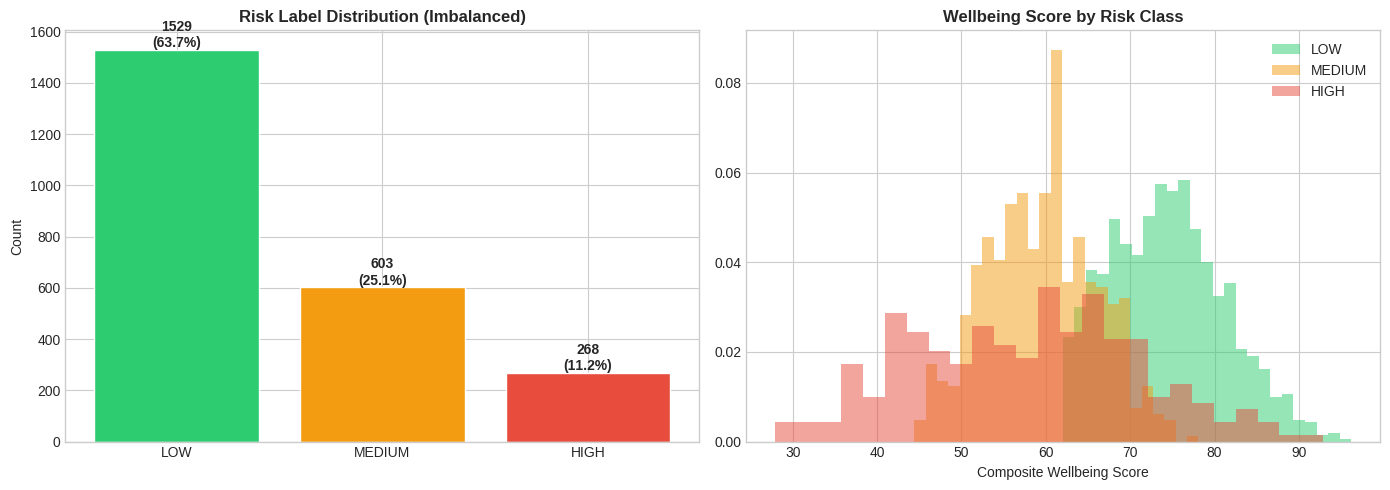

In [3]:
# ============================================================
# EDA CHART 1: CLASS DISTRIBUTION (Critical for Classification)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {'LOW': '#2ecc71', 'MEDIUM': '#f39c12', 'HIGH': '#e74c3c'}
counts = df['risk_label'].value_counts()

# Bar chart with percentages
bars = axes[0].bar(counts.index, counts.values,
                   color=[colors[l] for l in counts.index], edgecolor='white')
for bar, count in zip(bars, counts.values):
    pct = count / len(df) * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 f'{count}\n({pct:.1f}%)', ha='center', fontweight='bold')
axes[0].set_title('Risk Label Distribution (Imbalanced)', fontweight='bold')
axes[0].set_ylabel('Count')

# Show wellbeing score distribution per class
for label in ['LOW', 'MEDIUM', 'HIGH']:
    data = df[df['risk_label'] == label]['composite_wellbeing_score']
    axes[1].hist(data, bins=25, alpha=0.5, color=colors[label], label=label, density=True)
axes[1].set_title('Wellbeing Score by Risk Class', fontweight='bold')
axes[1].set_xlabel('Composite Wellbeing Score')
axes[1].legend()

plt.tight_layout()
plt.savefig('c3_chart1_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

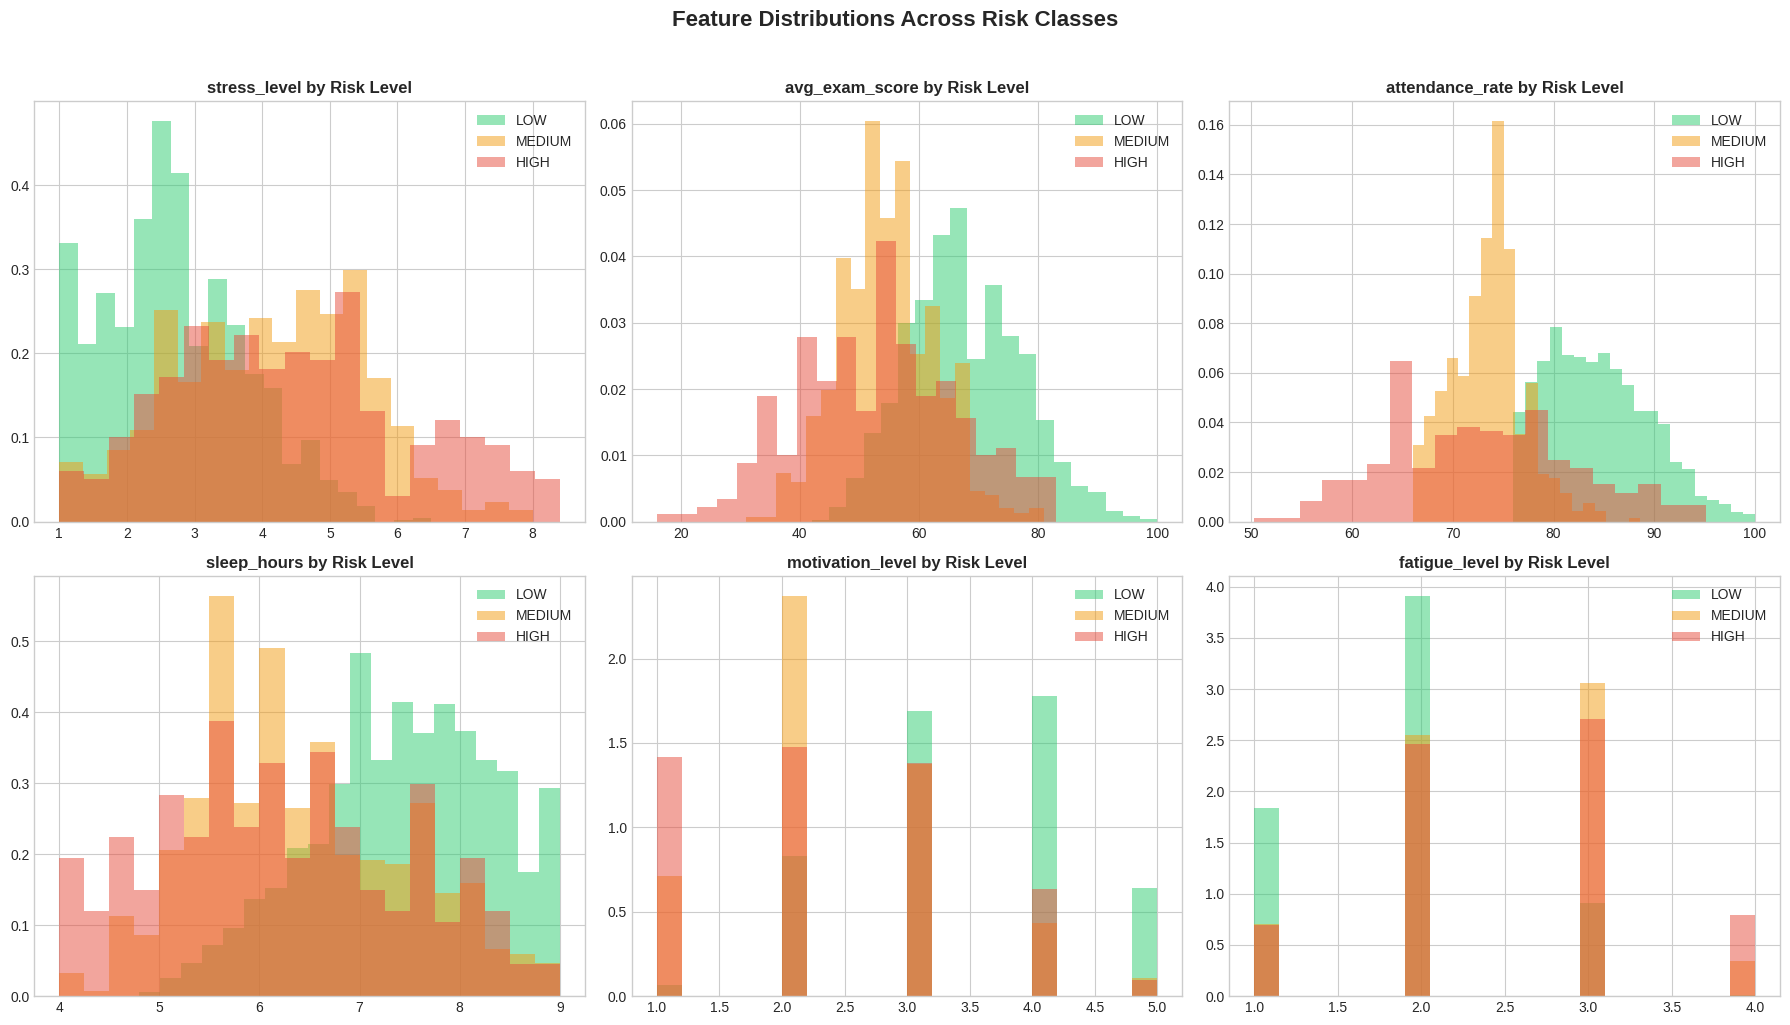

In [4]:
# ============================================================
# EDA CHART 2: KEY FEATURES BY RISK CLASS
# ============================================================
features_to_compare = ['stress_level', 'avg_exam_score', 'attendance_rate',
                       'sleep_hours', 'motivation_level', 'fatigue_level']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
order = ['LOW', 'MEDIUM', 'HIGH']

for i, feat in enumerate(features_to_compare):
    for label in order:
        data = df[df['risk_label'] == label][feat]
        axes[i].hist(data, bins=20, alpha=0.5, color=colors[label], label=label, density=True)
    axes[i].set_title(f'{feat} by Risk Level', fontweight='bold')
    axes[i].legend()

fig.suptitle('Feature Distributions Across Risk Classes', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('c3_chart2_features_by_risk.png', dpi=150, bbox_inches='tight')
plt.show()

####Section 3: Classification-Specific Feature Engineering

In [5]:
# ============================================================
# SECTION 3: CLASSIFICATION-SPECIFIC FEATURE ENGINEERING
# ============================================================
print("\n" + "=" * 60)
print("SECTION 3: FEATURE ENGINEERING (Classification-Specific)")
print("=" * 60)

# Feature 1: Risk Indicator Composite
# Combines stress, poor attendance, and fatigue into a single risk signal
df['risk_indicator_composite'] = (
    df['stress_level'] * (1 - df['attendance_rate'] / 100) * df['fatigue_level']
)
print(f"[+] risk_indicator_composite (mean: {df['risk_indicator_composite'].mean():.2f})")

# Feature 2: Wellbeing Gap
# How far the student is from the maximum possible wellbeing score
df['wellbeing_gap'] = 100 - df['composite_wellbeing_score']
print(f"[+] wellbeing_gap (mean: {df['wellbeing_gap'].mean():.2f})")

# Feature 3: Disengagement Score
# Sum of deficits in engagement metrics
df['disengagement_score'] = (
    (5 - df['motivation_level']) +
    (5 - df['class_participation']) +
    (5 - df['teacher_engagement_score'])
)
print(f"[+] disengagement_score (mean: {df['disengagement_score'].mean():.2f})")

# Feature 4: Attendance-Absence Ratio
df['attendance_absence_ratio'] = df['attendance_rate'] / (df['absence_count'] + 1)
print(f"[+] attendance_absence_ratio (mean: {df['attendance_absence_ratio'].mean():.2f})")

# Feature 5: Stress-Resilience Ratio
# How much stress relative to recovery capacity (sleep)
df['stress_resilience_ratio'] = df['stress_level'] / (df['sleep_hours'] - 3)
print(f"[+] stress_resilience_ratio (mean: {df['stress_resilience_ratio'].mean():.2f})")

# Feature 6: Weekly Volatility (per student)
# How unstable is the student's wellbeing over weeks
volatility = df.groupby('student_id')['composite_wellbeing_score'].std().reset_index()
volatility.columns = ['student_id', 'weekly_volatility']
df = df.merge(volatility, on='student_id', how='left')
print(f"[+] weekly_volatility (mean: {df['weekly_volatility'].mean():.2f})")


SECTION 3: FEATURE ENGINEERING (Classification-Specific)
[+] risk_indicator_composite (mean: 1.70)
[+] wellbeing_gap (mean: 31.26)
[+] disengagement_score (mean: 4.77)
[+] attendance_absence_ratio (mean: 30.88)
[+] stress_resilience_ratio (mean: 1.02)
[+] weekly_volatility (mean: 4.00)


####Section 4; Data Preprocessing


SECTION 4: PREPROCESSING (RobustScaler + SMOTE)
Features: 29
Samples: 2400

Class distribution before SMOTE:
risk_encoded
0    1529
1     603
2     268
Name: count, dtype: int64

--- Chi-Squared Feature Selection ---
Top 15 features:
                  Feature  Chi2_Score      P_Value
 risk_indicator_composite  131.369479 2.974953e-29
         motivation_level   78.261985 1.013038e-17
             stress_level   76.267633 2.745958e-17
  stress_resilience_ratio   74.480334 6.711211e-17
            wellbeing_gap   71.433093 3.079647e-16
    academic_stress_index   67.878714 1.821061e-15
            absence_count   67.430963 2.277993e-15
            fatigue_level   65.696082 5.423468e-15
 attendance_absence_ratio   60.572653 7.027738e-14
      disengagement_score   56.808983 4.614090e-13
            anxiety_level   56.443564 5.539056e-13
              study_hours   54.363308 1.567320e-12
composite_wellbeing_score   48.037741 3.704563e-11
          attendance_rate   45.698363 1.193236e-10


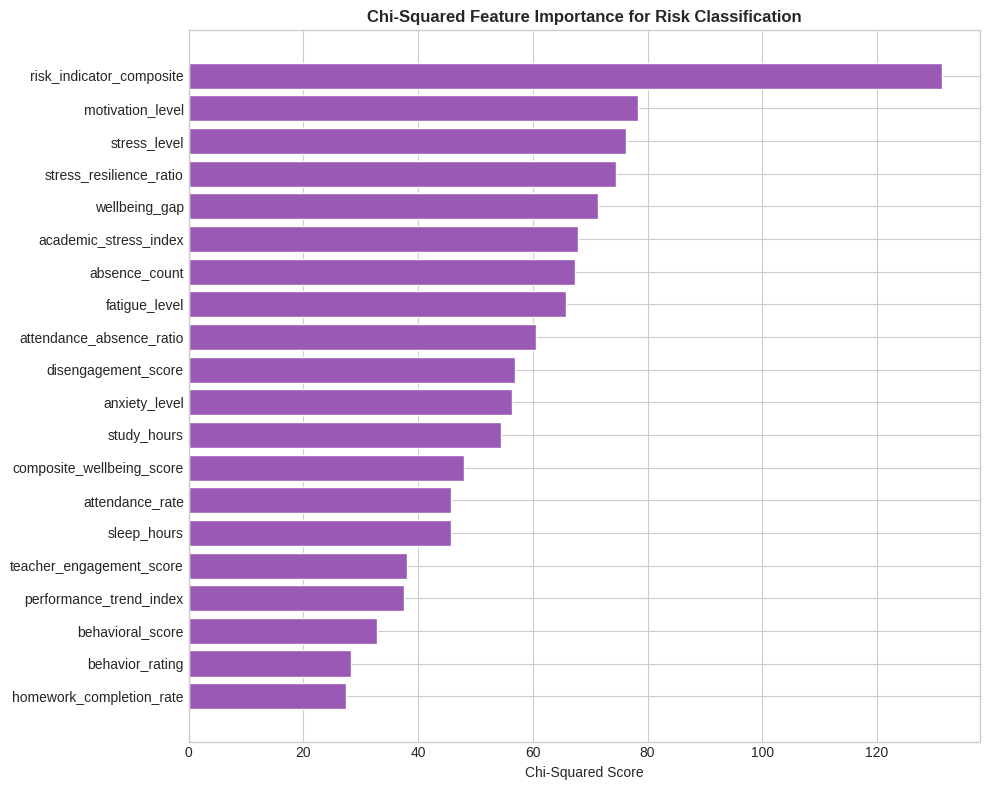


--- Stratified Split ---
Train: 1920 | Test: 480
Train class distribution:
risk_encoded
0    1223
1     482
2     215
Name: count, dtype: int64
Test class distribution:
risk_encoded
0    306
1    121
2     53
Name: count, dtype: int64

[OK] RobustScaler applied

[OK] SMOTE applied
Before SMOTE: {0: np.int64(1223), 1: np.int64(482), 2: np.int64(215)}
After SMOTE:  {0: np.int64(1223), 1: np.int64(1223), 2: np.int64(1223)}

PART 1 COMPLETE: EDA & Preprocessing done!
Proceed to Part 2 for Model Training & Evaluation.


In [6]:
# ============================================================
# SECTION 4: DATA PREPROCESSING
# ============================================================
print("\n" + "=" * 60)
print("SECTION 4: PREPROCESSING (RobustScaler + SMOTE)")
print("=" * 60)

# Encode target variable (ordinal: LOW=0, MEDIUM=1, HIGH=2)
le = LabelEncoder()
# Custom ordering to preserve risk severity
label_mapping = {'LOW': 0, 'MEDIUM': 1, 'HIGH': 2}
df['risk_encoded'] = df['risk_label'].map(label_mapping)

# Prepare features
drop_cols = ['student_id', 'risk_label', 'risk_encoded', 'next_week_wellbeing_score']
feature_cols = [c for c in df.columns if c not in drop_cols]
X = df[feature_cols].copy()
y = df['risk_encoded'].copy()

print(f"Features: {X.shape[1]}")
print(f"Samples: {X.shape[0]}")
print(f"\nClass distribution before SMOTE:")
print(y.value_counts().sort_index())

# --- Chi-Squared Feature Selection ---
# Select the top features most relevant to the categorical target
# Chi-squared test measures dependency between features and target

# Scale features to positive values for chi2 (using MinMax temporarily)
from sklearn.preprocessing import MinMaxScaler
X_pos = MinMaxScaler().fit_transform(X)

chi2_scores, p_values = chi2(X_pos, y)
chi2_df = pd.DataFrame({
    'Feature': X.columns,
    'Chi2_Score': chi2_scores,
    'P_Value': p_values
}).sort_values('Chi2_Score', ascending=False)

print("\n--- Chi-Squared Feature Selection ---")
print("Top 15 features:")
print(chi2_df.head(15).to_string(index=False))

# Select top features (p_value < 0.05)
significant_features = chi2_df[chi2_df['P_Value'] < 0.05]['Feature'].tolist()
print(f"\nSignificant features (p < 0.05): {len(significant_features)}")

# Visualize Chi-Squared scores
fig, ax = plt.subplots(figsize=(10, 8))
top_chi2 = chi2_df.head(20)
ax.barh(top_chi2['Feature'], top_chi2['Chi2_Score'], color='#9b59b6', edgecolor='white')
ax.set_title('Chi-Squared Feature Importance for Risk Classification', fontweight='bold')
ax.set_xlabel('Chi-Squared Score')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('c3_chart3_chi2_selection.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Stratified Train/Test Split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n--- Stratified Split ---")
print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")
print(f"Train class distribution:\n{y_train.value_counts().sort_index()}")
print(f"Test class distribution:\n{y_test.value_counts().sort_index()}")

# --- RobustScaler ---
# Uses median and IQR (not mean/std), making it robust to outliers
# This is unique to Colab 3 (Colab 1 uses MinMaxScaler, Colab 4 uses StandardScaler)
robust_scaler = RobustScaler()
X_train_scaled = pd.DataFrame(
    robust_scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    robust_scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)
print("\n[OK] RobustScaler applied")

# --- SMOTE (Synthetic Minority Oversampling) ---
# Creates synthetic samples for minority classes (MEDIUM, HIGH)
# This balances the dataset so the model doesn't become biased toward LOW
if HAS_SMOTE:
    smote = SMOTE(random_state=42)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)
    print(f"\n[OK] SMOTE applied")
    print(f"Before SMOTE: {dict(y_train.value_counts().sort_index())}")
    print(f"After SMOTE:  {dict(pd.Series(y_train_resampled).value_counts().sort_index())}")
else:
    X_train_resampled, y_train_resampled = X_train_scaled, y_train
    print("[SKIP] SMOTE not available, using original distribution")

print("\n" + "=" * 60)
print("PART 1 COMPLETE: EDA & Preprocessing done!")
print("Proceed to Part 2 for Model Training & Evaluation.")
print("=" * 60)

#### Section 5: Model Training

In [7]:
# ============================================================
# SETUP
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler, LabelEncoder, label_binarize, MinMaxScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, roc_auc_score, roc_curve, auc, precision_recall_curve,
                             cohen_kappa_score, matthews_corrcoef)
from sklearn.decomposition import PCA
import joblib
import warnings
warnings.filterwarnings('ignore')

try:
    import xgboost as xgb
    HAS_XGB = True
except: HAS_XGB = False

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except: HAS_SMOTE = False

try:
    import shap
    HAS_SHAP = True
except: HAS_SHAP = False

plt.style.use('seaborn-v0_8-whitegrid')

# --- Recreate data pipeline ---
df = pd.read_csv('student_wellbeing_dataset.csv')
df['risk_indicator_composite'] = df['stress_level'] * (1 - df['attendance_rate']/100) * df['fatigue_level']
df['wellbeing_gap'] = 100 - df['composite_wellbeing_score']
df['disengagement_score'] = (5-df['motivation_level']) + (5-df['class_participation']) + (5-df['teacher_engagement_score'])
df['attendance_absence_ratio'] = df['attendance_rate'] / (df['absence_count'] + 1)
df['stress_resilience_ratio'] = df['stress_level'] / (df['sleep_hours'] - 3)
vol = df.groupby('student_id')['composite_wellbeing_score'].std().reset_index()
vol.columns = ['student_id', 'weekly_volatility']
df = df.merge(vol, on='student_id', how='left')

label_mapping = {'LOW': 0, 'MEDIUM': 1, 'HIGH': 2}
df['risk_encoded'] = df['risk_label'].map(label_mapping)
drop_cols = ['student_id', 'risk_label', 'risk_encoded', 'next_week_wellbeing_score']
X = df[[c for c in df.columns if c not in drop_cols]]
y = df['risk_encoded']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
robust_scaler = RobustScaler()
X_train_scaled = pd.DataFrame(robust_scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(robust_scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

if HAS_SMOTE:
    smote = SMOTE(random_state=42)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)
else:
    X_train_resampled, y_train_resampled = X_train_scaled, y_train

class_names = ['LOW', 'MEDIUM', 'HIGH']
all_results = {}
all_models = {}
all_predictions = {}
colors_bar = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']

print("=" * 60)
print("SECTION 5: MODEL TRAINING")
print("=" * 60)

SECTION 5: MODEL TRAINING


In [8]:
# ============================================================
# MODEL 1: RANDOM FOREST CLASSIFIER
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 1: RANDOM FOREST CLASSIFIER")
print("#" * 50)

rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced']
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42), rf_params,
    n_iter=20, cv=StratifiedKFold(5), scoring='f1_macro', n_jobs=-1, random_state=42
)
rf_search.fit(X_train_resampled, y_train_resampled)
y_pred_rf = rf_search.predict(X_test_scaled)
print(f"Best params: {rf_search.best_params_}")
print(f"\n{classification_report(y_test, y_pred_rf, target_names=class_names)}")

all_results['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'F1_Macro': f1_score(y_test, y_pred_rf, average='macro'),
    'F1_Weighted': f1_score(y_test, y_pred_rf, average='weighted'),
    'Kappa': cohen_kappa_score(y_test, y_pred_rf),
    'MCC': matthews_corrcoef(y_test, y_pred_rf)
}
all_models['Random Forest'] = rf_search.best_estimator_
all_predictions['Random Forest'] = y_pred_rf


##################################################
# MODEL 1: RANDOM FOREST CLASSIFIER
##################################################
Best params: {'n_estimators': 300, 'min_samples_split': 2, 'max_depth': None, 'class_weight': 'balanced'}

              precision    recall  f1-score   support

         LOW       1.00      1.00      1.00       306
      MEDIUM       0.99      0.98      0.98       121
        HIGH       0.95      1.00      0.97        53

    accuracy                           0.99       480
   macro avg       0.98      0.99      0.98       480
weighted avg       0.99      0.99      0.99       480



In [9]:
# ============================================================
# MODEL 2: XGBOOST CLASSIFIER
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 2: XGBOOST CLASSIFIER")
print("#" * 50)

if HAS_XGB:
    xgb_params = {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.8, 1.0]
    }
    xgb_search = RandomizedSearchCV(
        xgb.XGBClassifier(random_state=42, eval_metric='mlogloss', use_label_encoder=False),
        xgb_params, n_iter=20, cv=StratifiedKFold(5), scoring='f1_macro', n_jobs=-1, random_state=42
    )
    xgb_search.fit(X_train_resampled, y_train_resampled)
    y_pred_xgb = xgb_search.predict(X_test_scaled)
    print(f"Best params: {xgb_search.best_params_}")
    print(f"\n{classification_report(y_test, y_pred_xgb, target_names=class_names)}")

    all_results['XGBoost'] = {
        'Accuracy': accuracy_score(y_test, y_pred_xgb),
        'F1_Macro': f1_score(y_test, y_pred_xgb, average='macro'),
        'F1_Weighted': f1_score(y_test, y_pred_xgb, average='weighted'),
        'Kappa': cohen_kappa_score(y_test, y_pred_xgb),
        'MCC': matthews_corrcoef(y_test, y_pred_xgb)
    }
    all_models['XGBoost'] = xgb_search.best_estimator_
    all_predictions['XGBoost'] = y_pred_xgb
else:
    print("[SKIP] XGBoost not installed")



##################################################
# MODEL 2: XGBOOST CLASSIFIER
##################################################
Best params: {'subsample': 1.0, 'n_estimators': 100, 'max_depth': 7, 'learning_rate': 0.1}

              precision    recall  f1-score   support

         LOW       1.00      1.00      1.00       306
      MEDIUM       1.00      0.99      1.00       121
        HIGH       0.98      1.00      0.99        53

    accuracy                           1.00       480
   macro avg       0.99      1.00      1.00       480
weighted avg       1.00      1.00      1.00       480



In [10]:
# ============================================================
# MODEL 3: SVM (RBF Kernel)
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 3: SVM (RBF Kernel)")
print("#" * 50)

svm_params = {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto'], 'kernel': ['rbf']}
svm_search = RandomizedSearchCV(
    SVC(probability=True, random_state=42, class_weight='balanced'),
    svm_params, n_iter=6, cv=StratifiedKFold(5), scoring='f1_macro', n_jobs=-1, random_state=42
)
svm_search.fit(X_train_resampled, y_train_resampled)
y_pred_svm = svm_search.predict(X_test_scaled)
print(f"Best params: {svm_search.best_params_}")
print(f"\n{classification_report(y_test, y_pred_svm, target_names=class_names)}")

all_results['SVM'] = {
    'Accuracy': accuracy_score(y_test, y_pred_svm),
    'F1_Macro': f1_score(y_test, y_pred_svm, average='macro'),
    'F1_Weighted': f1_score(y_test, y_pred_svm, average='weighted'),
    'Kappa': cohen_kappa_score(y_test, y_pred_svm),
    'MCC': matthews_corrcoef(y_test, y_pred_svm)
}
all_models['SVM'] = svm_search.best_estimator_
all_predictions['SVM'] = y_pred_svm


##################################################
# MODEL 3: SVM (RBF Kernel)
##################################################
Best params: {'kernel': 'rbf', 'gamma': 'scale', 'C': 10}

              precision    recall  f1-score   support

         LOW       0.99      0.96      0.97       306
      MEDIUM       0.88      0.94      0.91       121
        HIGH       0.88      0.87      0.88        53

    accuracy                           0.95       480
   macro avg       0.92      0.92      0.92       480
weighted avg       0.95      0.95      0.95       480



In [11]:
# ============================================================
# MODEL 4: K-NEAREST NEIGHBORS
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 4: K-NEAREST NEIGHBORS")
print("#" * 50)

knn_params = {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']}
knn_search = RandomizedSearchCV(
    KNeighborsClassifier(), knn_params, n_iter=15, cv=StratifiedKFold(5), scoring='f1_macro', n_jobs=-1, random_state=42
)
knn_search.fit(X_train_resampled, y_train_resampled)
y_pred_knn = knn_search.predict(X_test_scaled)
print(f"Best params: {knn_search.best_params_}")
print(f"\n{classification_report(y_test, y_pred_knn, target_names=class_names)}")

all_results['KNN'] = {
    'Accuracy': accuracy_score(y_test, y_pred_knn),
    'F1_Macro': f1_score(y_test, y_pred_knn, average='macro'),
    'F1_Weighted': f1_score(y_test, y_pred_knn, average='weighted'),
    'Kappa': cohen_kappa_score(y_test, y_pred_knn),
    'MCC': matthews_corrcoef(y_test, y_pred_knn)
}
all_models['KNN'] = knn_search.best_estimator_
all_predictions['KNN'] = y_pred_knn


##################################################
# MODEL 4: K-NEAREST NEIGHBORS
##################################################
Best params: {'weights': 'distance', 'n_neighbors': 3, 'metric': 'manhattan'}

              precision    recall  f1-score   support

         LOW       0.96      0.90      0.93       306
      MEDIUM       0.80      0.83      0.82       121
        HIGH       0.66      0.81      0.73        53

    accuracy                           0.88       480
   macro avg       0.81      0.85      0.82       480
weighted avg       0.88      0.88      0.88       480



In [12]:
# ============================================================
# MODEL 5: MLP CLASSIFIER (Neural Network)
# ============================================================
print("\n" + "#" * 50)
print("# MODEL 5: MLP CLASSIFIER (Neural Network)")
print("#" * 50)

mlp_params = {
    'hidden_layer_sizes': [(64, 32), (128, 64), (100, 50, 25)],
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate': ['adaptive']
}
mlp_search = RandomizedSearchCV(
    MLPClassifier(max_iter=500, random_state=42), mlp_params,
    n_iter=12, cv=StratifiedKFold(5), scoring='f1_macro', n_jobs=-1, random_state=42
)
mlp_search.fit(X_train_resampled, y_train_resampled)
y_pred_mlp = mlp_search.predict(X_test_scaled)
print(f"Best params: {mlp_search.best_params_}")
print(f"\n{classification_report(y_test, y_pred_mlp, target_names=class_names)}")

all_results['MLP'] = {
    'Accuracy': accuracy_score(y_test, y_pred_mlp),
    'F1_Macro': f1_score(y_test, y_pred_mlp, average='macro'),
    'F1_Weighted': f1_score(y_test, y_pred_mlp, average='weighted'),
    'Kappa': cohen_kappa_score(y_test, y_pred_mlp),
    'MCC': matthews_corrcoef(y_test, y_pred_mlp)
}
all_models['MLP'] = mlp_search.best_estimator_
all_predictions['MLP'] = y_pred_mlp


##################################################
# MODEL 5: MLP CLASSIFIER (Neural Network)
##################################################
Best params: {'learning_rate': 'adaptive', 'hidden_layer_sizes': (64, 32), 'alpha': 0.0001, 'activation': 'tanh'}

              precision    recall  f1-score   support

         LOW       0.98      0.96      0.97       306
      MEDIUM       0.87      0.90      0.89       121
        HIGH       0.79      0.85      0.82        53

    accuracy                           0.93       480
   macro avg       0.88      0.90      0.89       480
weighted avg       0.93      0.93      0.93       480



#### Section 6: Comprehensive Evaluation & Visualization

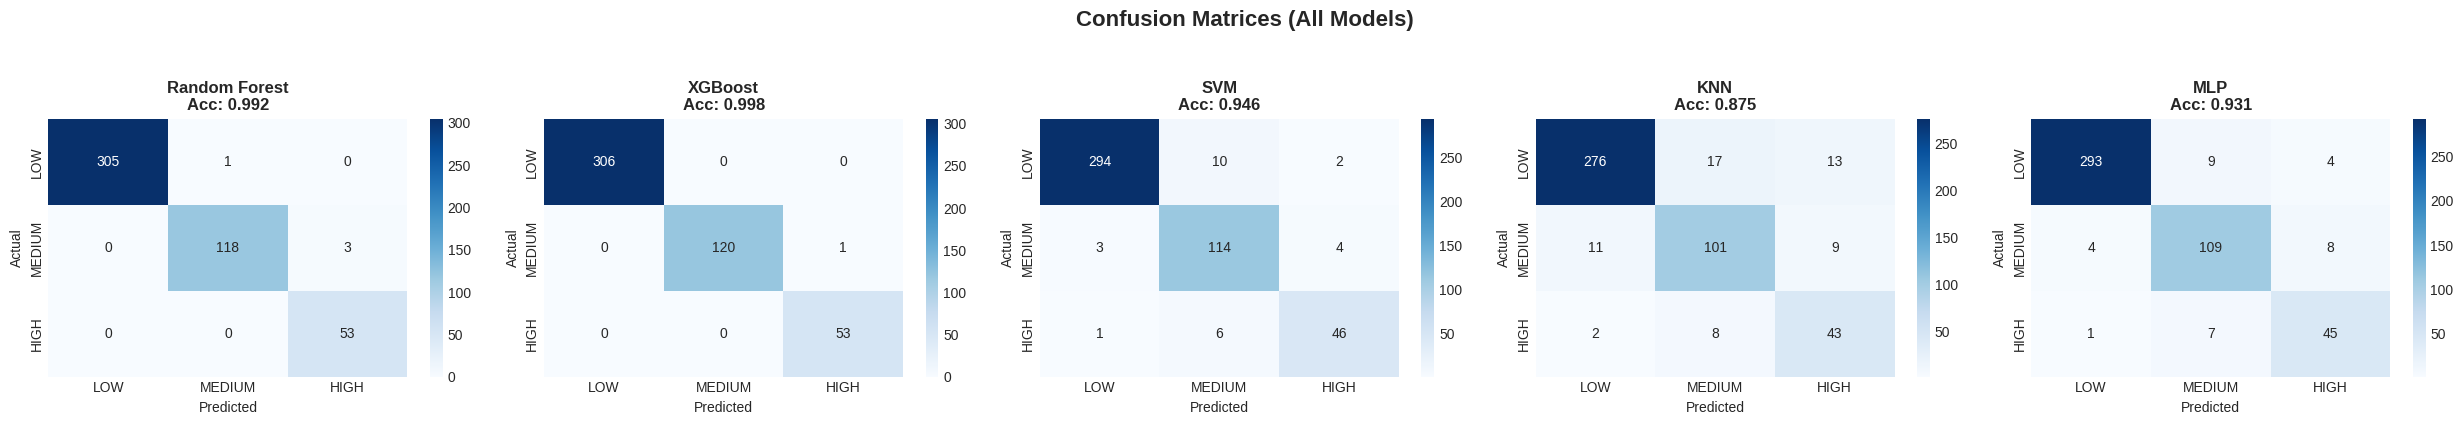

In [13]:
# ============================================================
# EVAL CHART 1: CONFUSION MATRICES (All Models)
# ============================================================
n_models = len(all_predictions)
fig, axes = plt.subplots(1, n_models, figsize=(5 * n_models, 4))
if n_models == 1: axes = [axes]

for i, (name, y_pred) in enumerate(all_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=class_names, yticklabels=class_names)
    axes[i].set_title(f'{name}\nAcc: {all_results[name]["Accuracy"]:.3f}', fontweight='bold')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

fig.suptitle('Confusion Matrices (All Models)', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig('c3_chart4_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

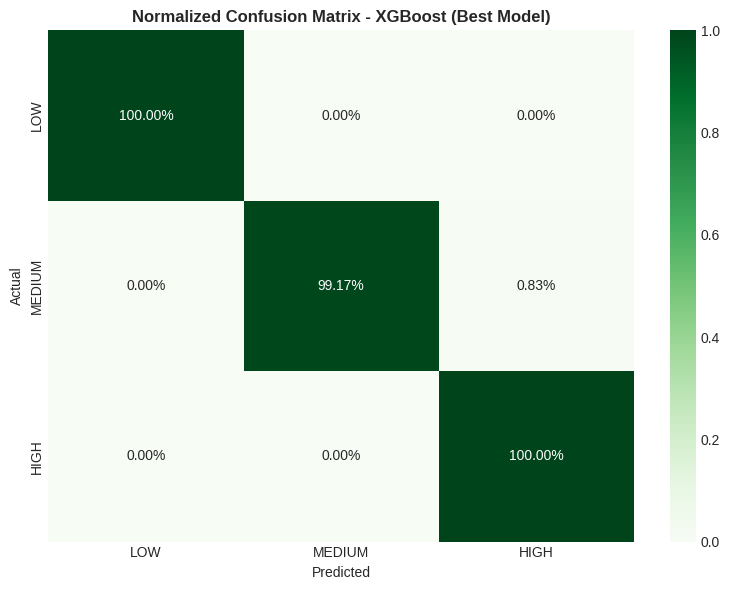

In [14]:
# ============================================================
# EVAL CHART 2: NORMALIZED CONFUSION MATRIX (Best Model)
# ============================================================
results_df = pd.DataFrame(all_results).T
best_name = results_df['F1_Macro'].idxmax()
best_pred = all_predictions[best_name]

cm_norm = confusion_matrix(y_test, best_pred, normalize='true')
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', ax=ax,
            xticklabels=class_names, yticklabels=class_names)
ax.set_title(f'Normalized Confusion Matrix - {best_name} (Best Model)', fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig('c3_chart5_normalized_cm.png', dpi=150, bbox_inches='tight')
plt.show()

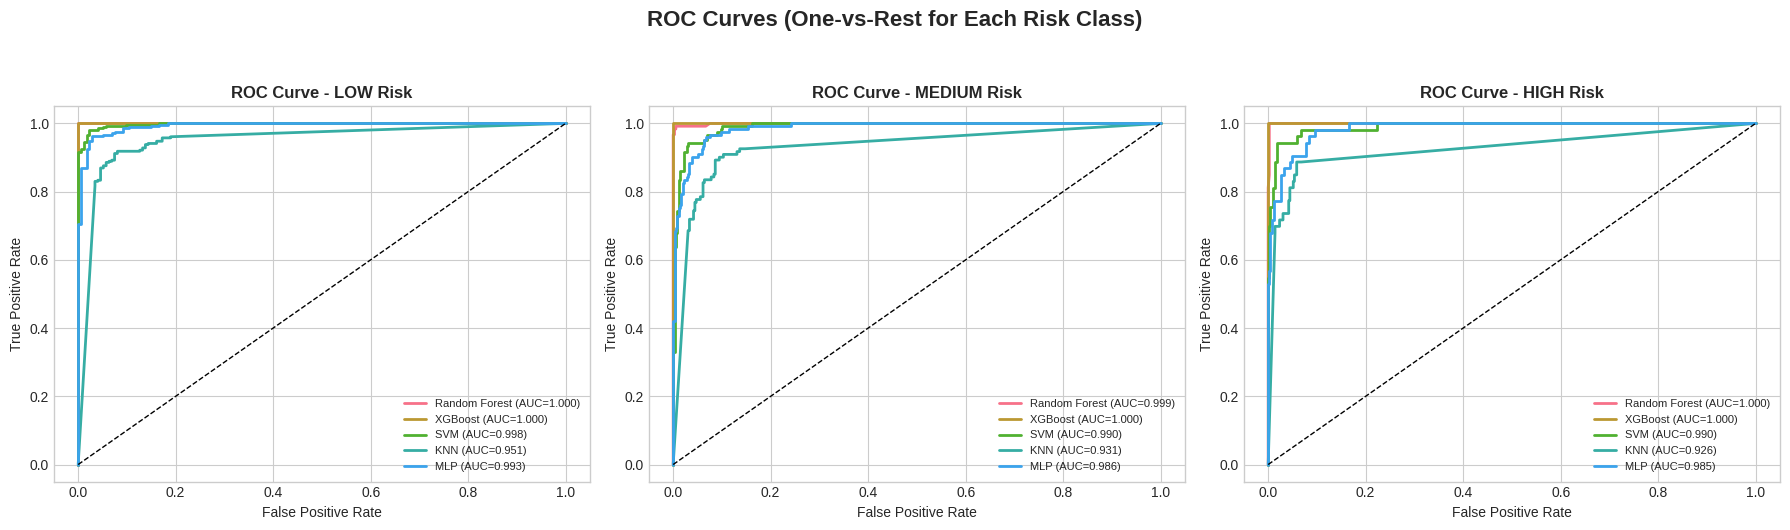

In [15]:
# ============================================================
# EVAL CHART 3: ROC CURVES (One-vs-Rest)
# ============================================================
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
line_colors = ['#2ecc71', '#f39c12', '#e74c3c']

for i, class_name in enumerate(class_names):
    for name, model in all_models.items():
        if hasattr(model, 'predict_proba'):
            y_prob = model.predict_proba(X_test_scaled)
            fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
            roc_auc_val = auc(fpr, tpr)
            axes[i].plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={roc_auc_val:.3f})')
    axes[i].plot([0, 1], [0, 1], 'k--', linewidth=1)
    axes[i].set_title(f'ROC Curve - {class_name} Risk', fontweight='bold')
    axes[i].set_xlabel('False Positive Rate')
    axes[i].set_ylabel('True Positive Rate')
    axes[i].legend(fontsize=8)

fig.suptitle('ROC Curves (One-vs-Rest for Each Risk Class)', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig('c3_chart6_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()


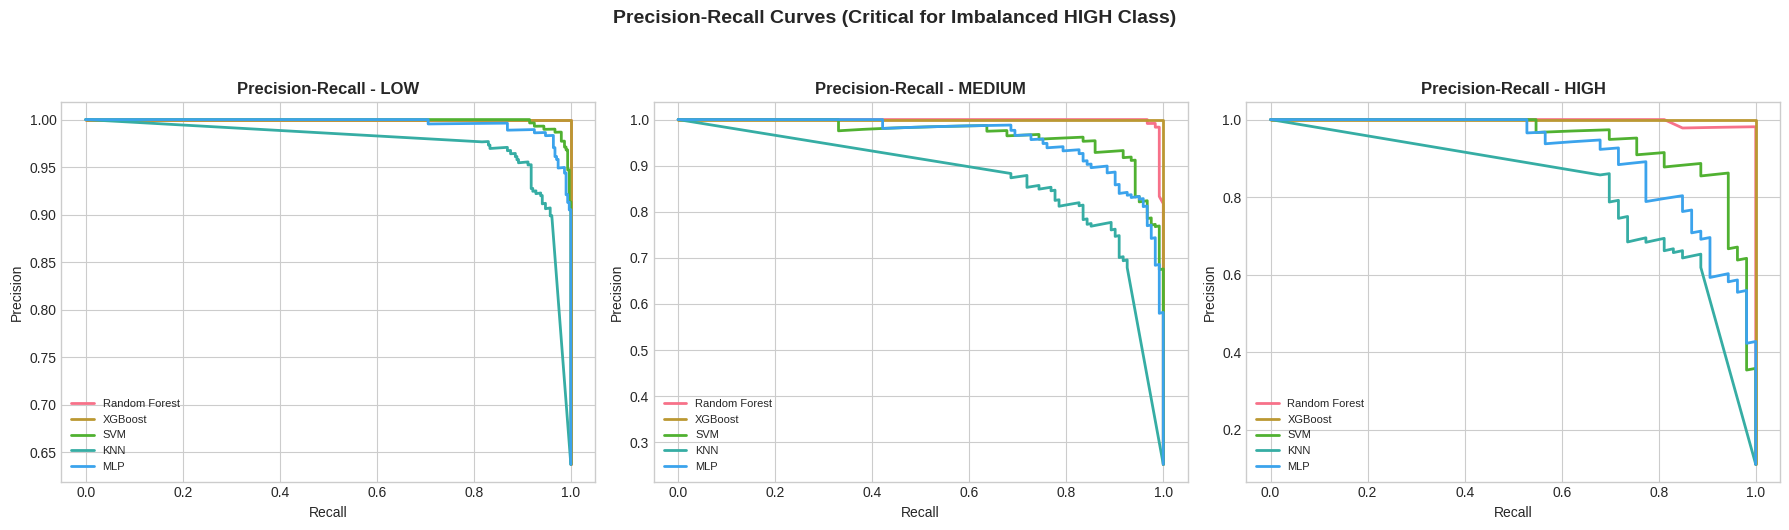

In [16]:
# ============================================================
# EVAL CHART 4: PRECISION-RECALL CURVES
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, class_name in enumerate(class_names):
    for name, model in all_models.items():
        if hasattr(model, 'predict_proba'):
            y_prob = model.predict_proba(X_test_scaled)
            prec, rec, _ = precision_recall_curve(y_test_bin[:, i], y_prob[:, i])
            axes[i].plot(rec, prec, linewidth=2, label=f'{name}')
    axes[i].set_title(f'Precision-Recall - {class_name}', fontweight='bold')
    axes[i].set_xlabel('Recall')
    axes[i].set_ylabel('Precision')
    axes[i].legend(fontsize=8)

fig.suptitle('Precision-Recall Curves (Critical for Imbalanced HIGH Class)', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.savefig('c3_chart7_precision_recall.png', dpi=150, bbox_inches='tight')
plt.show()

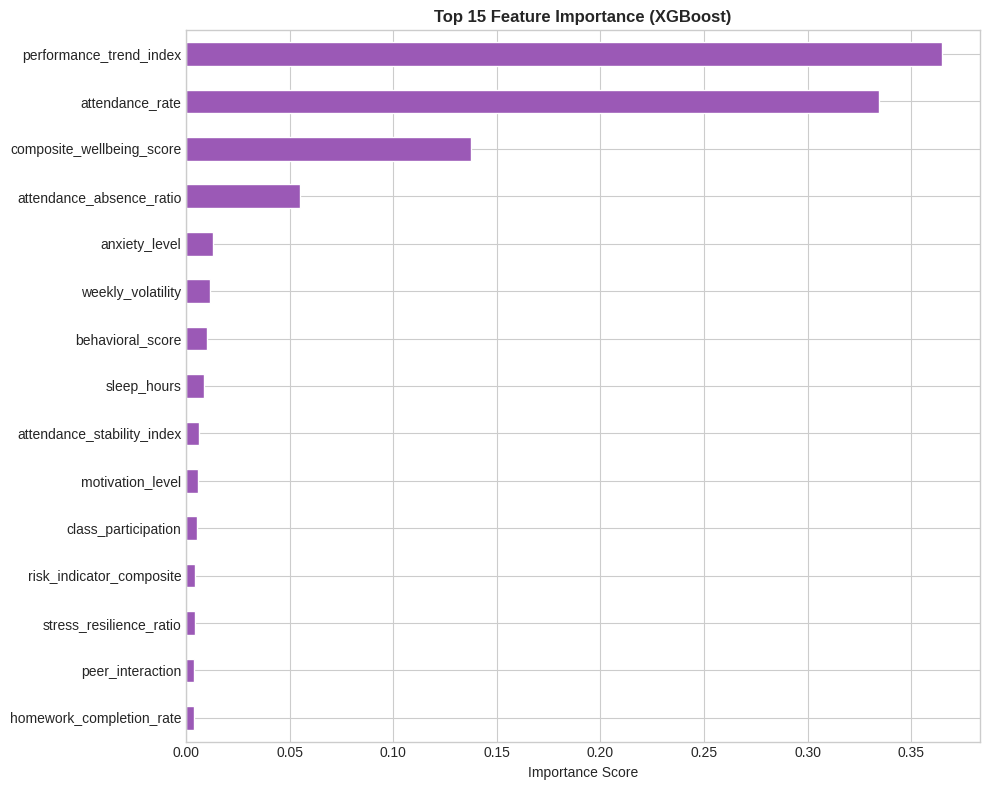

In [17]:
# ============================================================
# EVAL CHART 5: FEATURE IMPORTANCE (Best Tree Model)
# ============================================================
tree_models = {k: v for k, v in all_models.items() if hasattr(v, 'feature_importances_')}
if tree_models:
    best_tree_name = max(tree_models, key=lambda k: all_results[k]['F1_Macro'])
    importances = pd.Series(tree_models[best_tree_name].feature_importances_, index=X_train.columns)
    top_15 = importances.sort_values(ascending=True).tail(15)

    fig, ax = plt.subplots(figsize=(10, 8))
    top_15.plot(kind='barh', color='#9b59b6', edgecolor='white', ax=ax)
    ax.set_title(f'Top 15 Feature Importance ({best_tree_name})', fontweight='bold')
    ax.set_xlabel('Importance Score')
    plt.tight_layout()
    plt.savefig('c3_chart8_feature_importance.png', dpi=150, bbox_inches='tight')
    plt.show()

Generating SHAP values (may take a moment)...


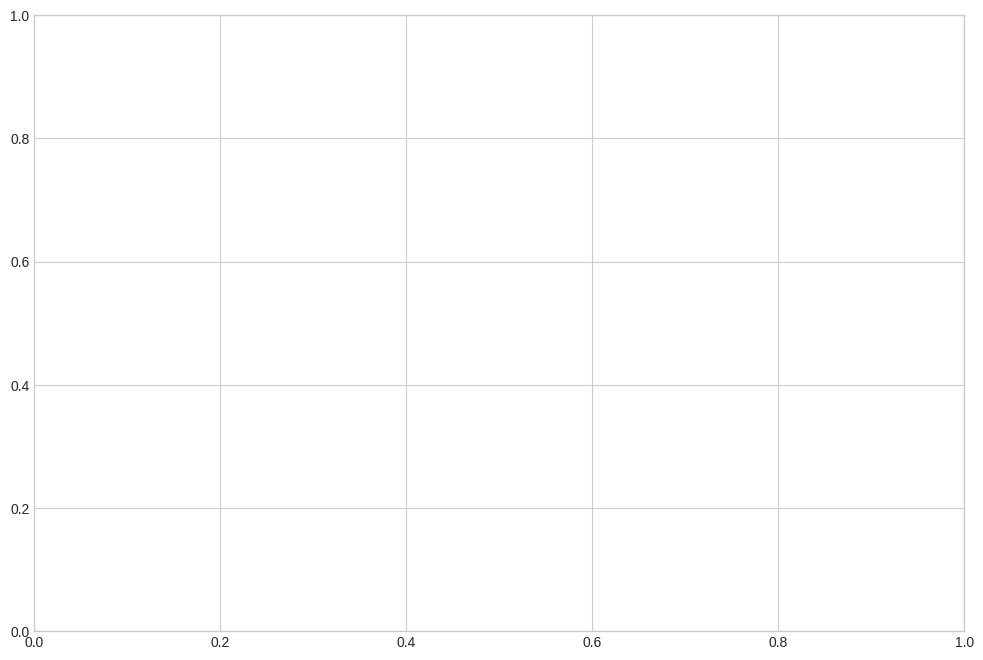

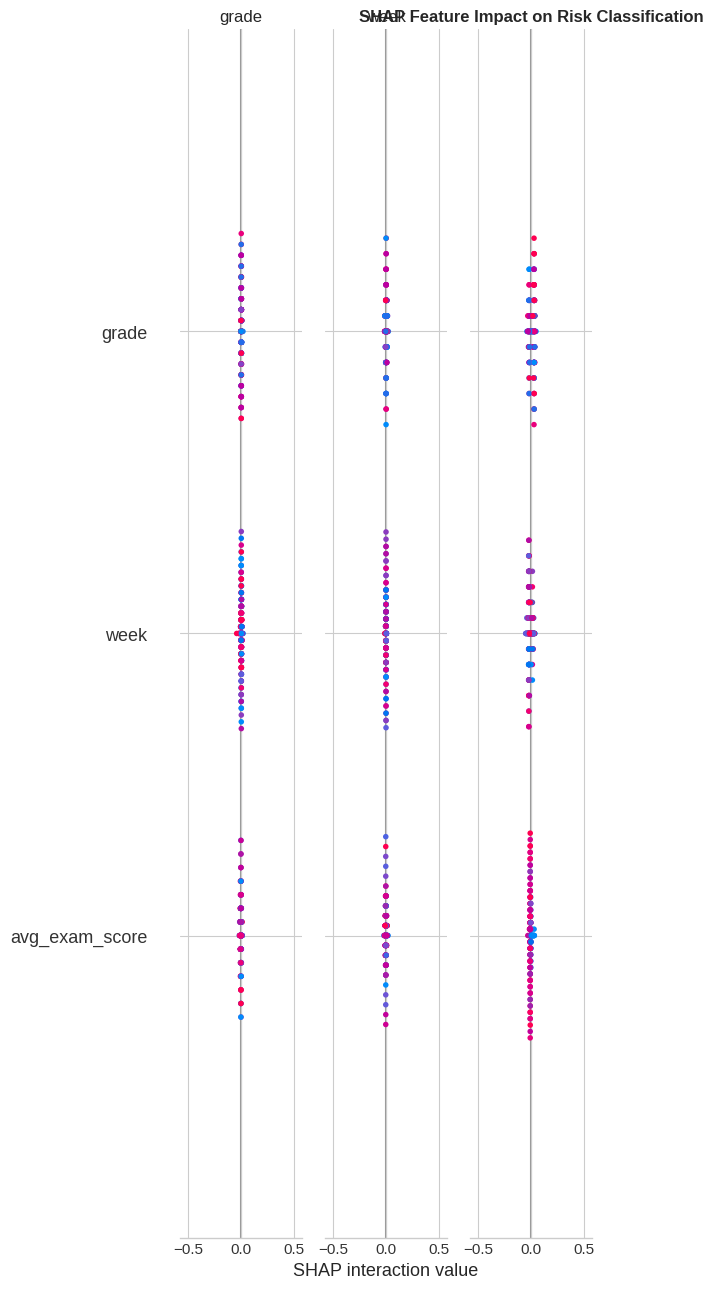

In [18]:
# ============================================================
# EVAL CHART 6: SHAP SUMMARY PLOT
# ============================================================
if HAS_SHAP and 'Random Forest' in all_models:
    print("Generating SHAP values (may take a moment)...")
    explainer = shap.TreeExplainer(all_models['Random Forest'])
    shap_values = explainer.shap_values(X_test_scaled.iloc[:200])  # Sample for speed

    fig, ax = plt.subplots(figsize=(12, 8))
    shap.summary_plot(shap_values, X_test_scaled.iloc[:200], class_names=class_names,
                      show=False, max_display=15)
    plt.title('SHAP Feature Impact on Risk Classification', fontweight='bold')
    plt.tight_layout()
    plt.savefig('c3_chart9_shap.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("[SKIP] SHAP plot (library not available or Random Forest not trained)")

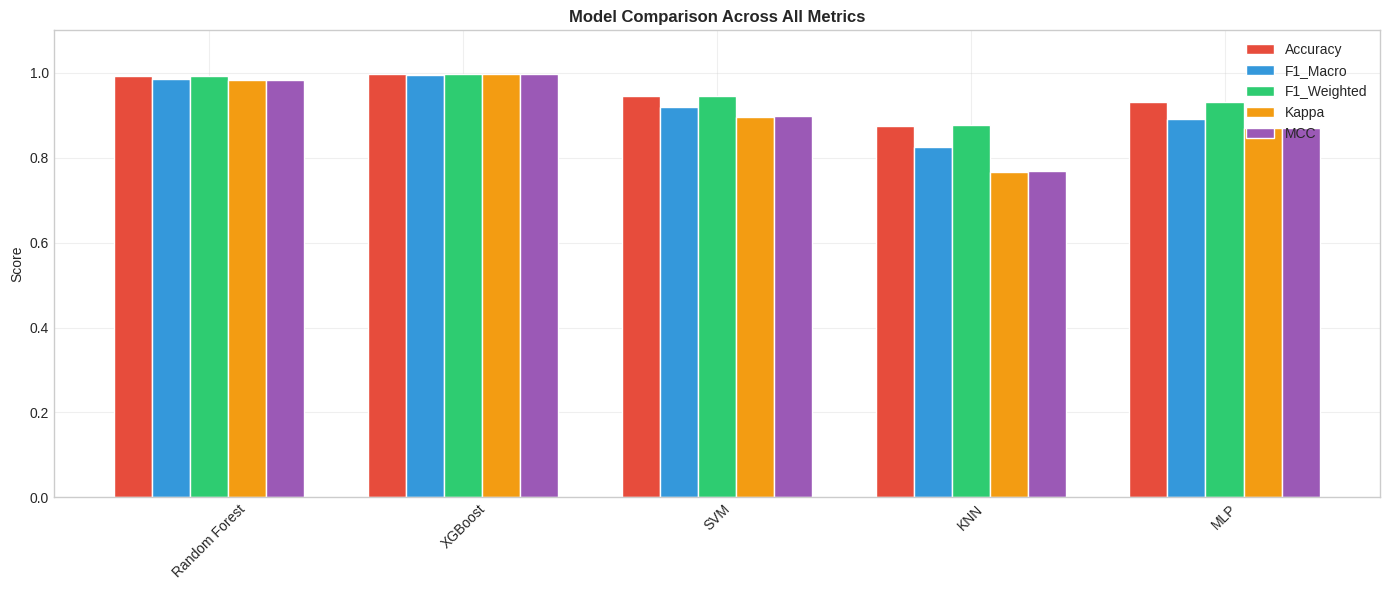

In [19]:
# ============================================================
# EVAL CHART 7: MODEL COMPARISON (Grouped Bar)
# ============================================================
fig, ax = plt.subplots(figsize=(14, 6))
metrics_to_plot = ['Accuracy', 'F1_Macro', 'F1_Weighted', 'Kappa', 'MCC']
x = np.arange(len(all_results))
width = 0.15

for i, metric in enumerate(metrics_to_plot):
    values = [all_results[m][metric] for m in all_results]
    bars = ax.bar(x + i * width, values, width, label=metric, color=colors_bar[i], edgecolor='white')

ax.set_xticks(x + width * 2)
ax.set_xticklabels(list(all_results.keys()), rotation=45)
ax.set_title('Model Comparison Across All Metrics', fontweight='bold')
ax.set_ylabel('Score')
ax.legend()
ax.set_ylim(0, 1.1)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('c3_chart10_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

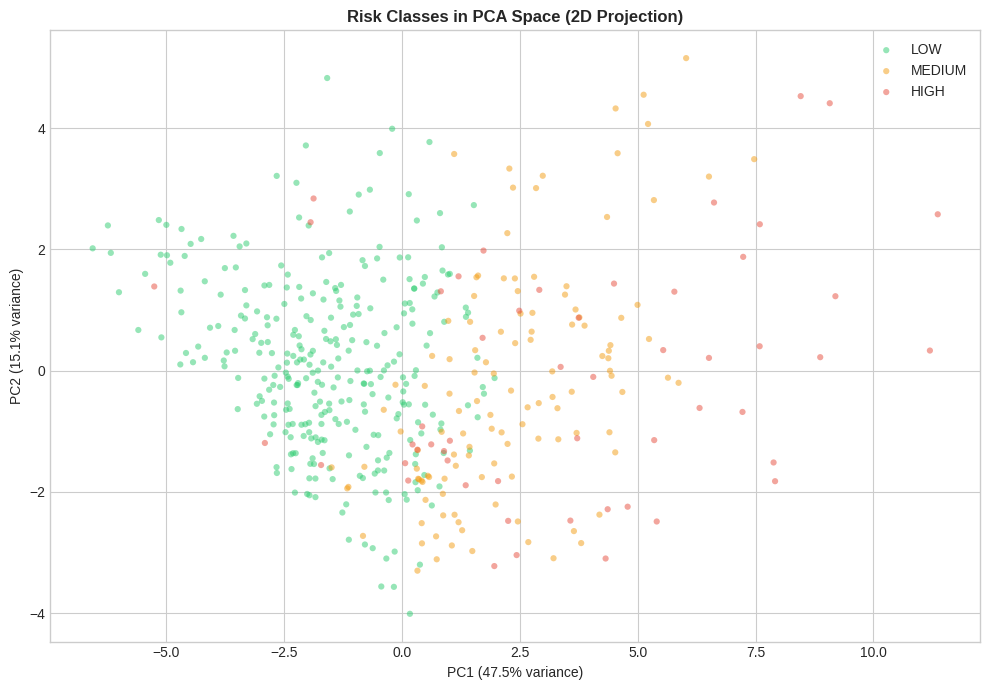

In [20]:
# ============================================================
# EVAL CHART 8: DECISION BOUNDARY (2D PCA Projection)
# ============================================================
pca = PCA(n_components=2)
X_test_pca = pca.fit_transform(X_test_scaled)

fig, ax = plt.subplots(figsize=(10, 7))
scatter_colors = {0: '#2ecc71', 1: '#f39c12', 2: '#e74c3c'}
for cls, name in enumerate(class_names):
    mask = y_test == cls
    ax.scatter(X_test_pca[mask, 0], X_test_pca[mask, 1], c=scatter_colors[cls],
               label=name, alpha=0.5, s=20, edgecolors='none')
ax.set_title('Risk Classes in PCA Space (2D Projection)', fontweight='bold')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.legend()
plt.tight_layout()
plt.savefig('c3_chart11_pca_boundary.png', dpi=150, bbox_inches='tight')
plt.show()

#### Section 7: Final Summary & Export

In [21]:
# ============================================================
# FINAL SUMMARY
# ============================================================
print("\n" + "=" * 70)
print("FINAL CLASSIFICATION MODEL COMPARISON")
print("=" * 70)
print(results_df.round(4).to_string())

print(f"\n*** BEST MODEL: {best_name} ***")
for metric, val in all_results[best_name].items():
    print(f"    {metric}: {val:.4f}")

# Save best model
joblib.dump(all_models[best_name], 'best_risk_classifier.pkl')
joblib.dump(robust_scaler, 'risk_scaler.pkl')
print(f"\nModel saved: best_risk_classifier.pkl")
print(f"Scaler saved: risk_scaler.pkl")

results_df.to_csv('risk_classification_results.csv')
print("Results saved: risk_classification_results.csv")

print("\n" + "=" * 60)
print("COLAB 3 COMPLETE: Risk Classification Model built!")
print("=" * 60)



FINAL CLASSIFICATION MODEL COMPARISON
               Accuracy  F1_Macro  F1_Weighted   Kappa     MCC
Random Forest    0.9917    0.9847       0.9917  0.9840  0.9840
XGBoost          0.9979    0.9955       0.9979  0.9960  0.9960
SVM              0.9458    0.9194       0.9463  0.8966  0.8972
KNN              0.8750    0.8248       0.8781  0.7664  0.7682
MLP              0.9312    0.8915       0.9322  0.8692  0.8696

*** BEST MODEL: XGBoost ***
    Accuracy: 0.9979
    F1_Macro: 0.9955
    F1_Weighted: 0.9979
    Kappa: 0.9960
    MCC: 0.9960

Model saved: best_risk_classifier.pkl
Scaler saved: risk_scaler.pkl
Results saved: risk_classification_results.csv

COLAB 3 COMPLETE: Risk Classification Model built!
